In [24]:
import kagglehub
import heapq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances, cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

Algorithm 2: Alternative agglomerative hierarchical clustering algorithm (single-linkage)

In [25]:
def find_max_sim(I, N, P):
    i1 = -1
    max_p_sim = -np.inf

    for i in range(N):
        if I[i] == i:
            if P[i]['sim'] > max_p_sim:
                max_p_sim = P[i]['sim']
                i1 = i

    i2 = I[P[i1]['index']]
    return max_p_sim, i1, i2

def single_linkage_alternative(documents, similarity_func): # I changed the algorithm to accept a similari
    N = len(documents) # Number of documents
    P = [{'index': -1, 'sim': -np.inf} for _ in range(N)] # Priority structure (list of dicts)
    I = np.zeros(N, dtype=int)  # Cluster activity indicator
    S = np.zeros((N, N)) # Similarity matrix
    L = []  # Fusion list

    for i in range(N):
        for j in range(N):
            S[i, j] = similarity_func(documents[i], documents[j])
            if i != j and P[i]['sim'] < S[i, j]:
                P[i]['sim'] = S[i, j]
                P[i]['index'] = j
        I[i] = i

    for k in range(N - 1):
        fusion_sim, i1, i2 = find_max_sim(I, N, P)
        P[i1]['sim'] = -1
        L.append([i1, i2, fusion_sim]) # record the merge

        for i in range(N):
            if I[i] == i and i != i2:
                S[i, i1] = max(S[i, i1], S[i, i2])
                S[i1, i] = max(S[i, i1], S[i, i2])
            if I[i] == i2:
                I[i] = i1
            if I[i] == i and i != i1 and S[i1, i] > P[i]['sim']:
                P[i]['sim'] = S[i1, i]
                P[i]['index'] = i1
    return L

In [26]:
sim_mat = np.array([
    [10, 6, 0, 0, 0, 0, 0, 0, 0],
    [6, 10, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 10, 5, 3, 3, 1, 1, 0],
    [0, 0, 5, 10, 1, 2, 1, 1, 0],
    [0, 0, 3, 1, 10, 4, 1, 2, 0],
    [0, 0, 3, 2, 4, 10, 1, 4, 0],
    [0, 0, 1, 1, 1, 1, 10, 1, 0],
    [0, 0, 1, 1, 2, 4, 1, 10, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 10]
])

def similarity_func(doc1, doc2):
    return sim_mat[doc1, doc2]

documents = list(range(sim_mat.shape[0]))
L = single_linkage_alternative(documents, similarity_func)
print("Fusion list L:")
for merge in L:
    print(merge)

Fusion list L:
[0, np.int64(1), np.float64(6.0)]
[2, np.int64(3), np.float64(5.0)]
[4, np.int64(5), np.float64(4.0)]
[7, np.int64(4), np.float64(4.0)]
[2, np.int64(7), np.float64(3.0)]
[6, np.int64(2), np.float64(1.0)]
[0, np.int64(6), np.float64(0.0)]
[8, np.int64(0), np.float64(0.0)]


In [27]:
def convertToScypi(L, N, maxSim):
    Z = []
    cluster_id = N
    cluster_map = {i: i for i in range(N)}

    for merge in L:
        i1, i2, sim = merge
        c1 = cluster_map[i1]
        c2 = cluster_map[i2]
        dist = maxSim - sim
        if c1 < N:
            c1_size = 1
        else:
            c1_size = Z[c1 - N][3]
        
        if c2 < N:
            c2_size = 1
        else:
            c2_size = Z[c2 - N][3]

        newCluster_size = c1_size + c2_size

        if c1 < c2: # here I changed i1 <-- c1 and i2 <-- c2 ==> this was the key to optain the same visualization of dendrogram 
            Z.append([float(c1), float(c2), float(dist), float(newCluster_size)])
        else:
            Z.append([float(c2), float(c1), float(dist), float(newCluster_size)])
        cluster_map[i1] = cluster_id
        for key in cluster_map:
            if cluster_map[key] == c2:
                cluster_map[key] = cluster_id
        cluster_id += 1
    return np.array(Z)

In [28]:
def plot_dendrogram(Z, fig_size=(10,7), title='Dendrogram', xlabel='Samples', ylabel='Distance', save_as_png=False):
    plt.figure(figsize=fig_size)
    sch.dendrogram(Z)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if save_as_png:
        plt.savefig('{}_Algo2.png'.format(title))
    plt.show()

# Dendrogram visualization

Test the given matrix with our Algo2 and scipy's dendrogramm 

Fusion List L:
[0, np.int64(1), np.float64(6.0)]
[2, np.int64(3), np.float64(5.0)]
[4, np.int64(5), np.float64(4.0)]
[7, np.int64(4), np.float64(4.0)]
[2, np.int64(7), np.float64(3.0)]
[6, np.int64(2), np.float64(1.0)]
[0, np.int64(6), np.float64(0.0)]
[8, np.int64(0), np.float64(0.0)]


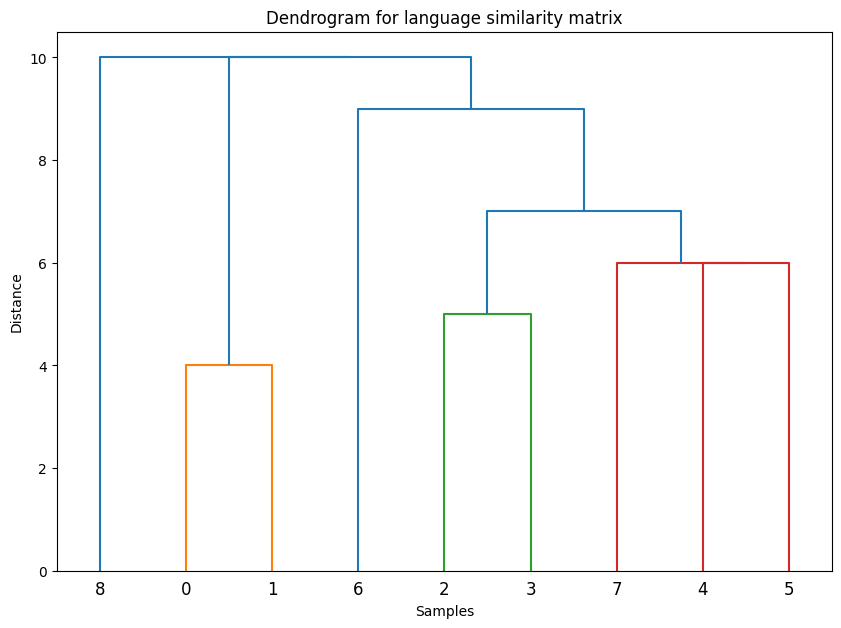

<Figure size 640x480 with 0 Axes>

In [29]:

res_for_sim_mat = L
print("Fusion List L:")
for merge in res_for_sim_mat:
    print(merge)

Z = convertToScypi(res_for_sim_mat, sim_mat.shape[0], np.max(sim_mat))
plot_dendrogram(Z, fig_size=(10,7), title='Dendrogram for language similarity matrix', save_as_png=True)
plt.savefig('Dendrogram for language similarity matrix')

Test with Mall_Customers dataset (from [Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python))

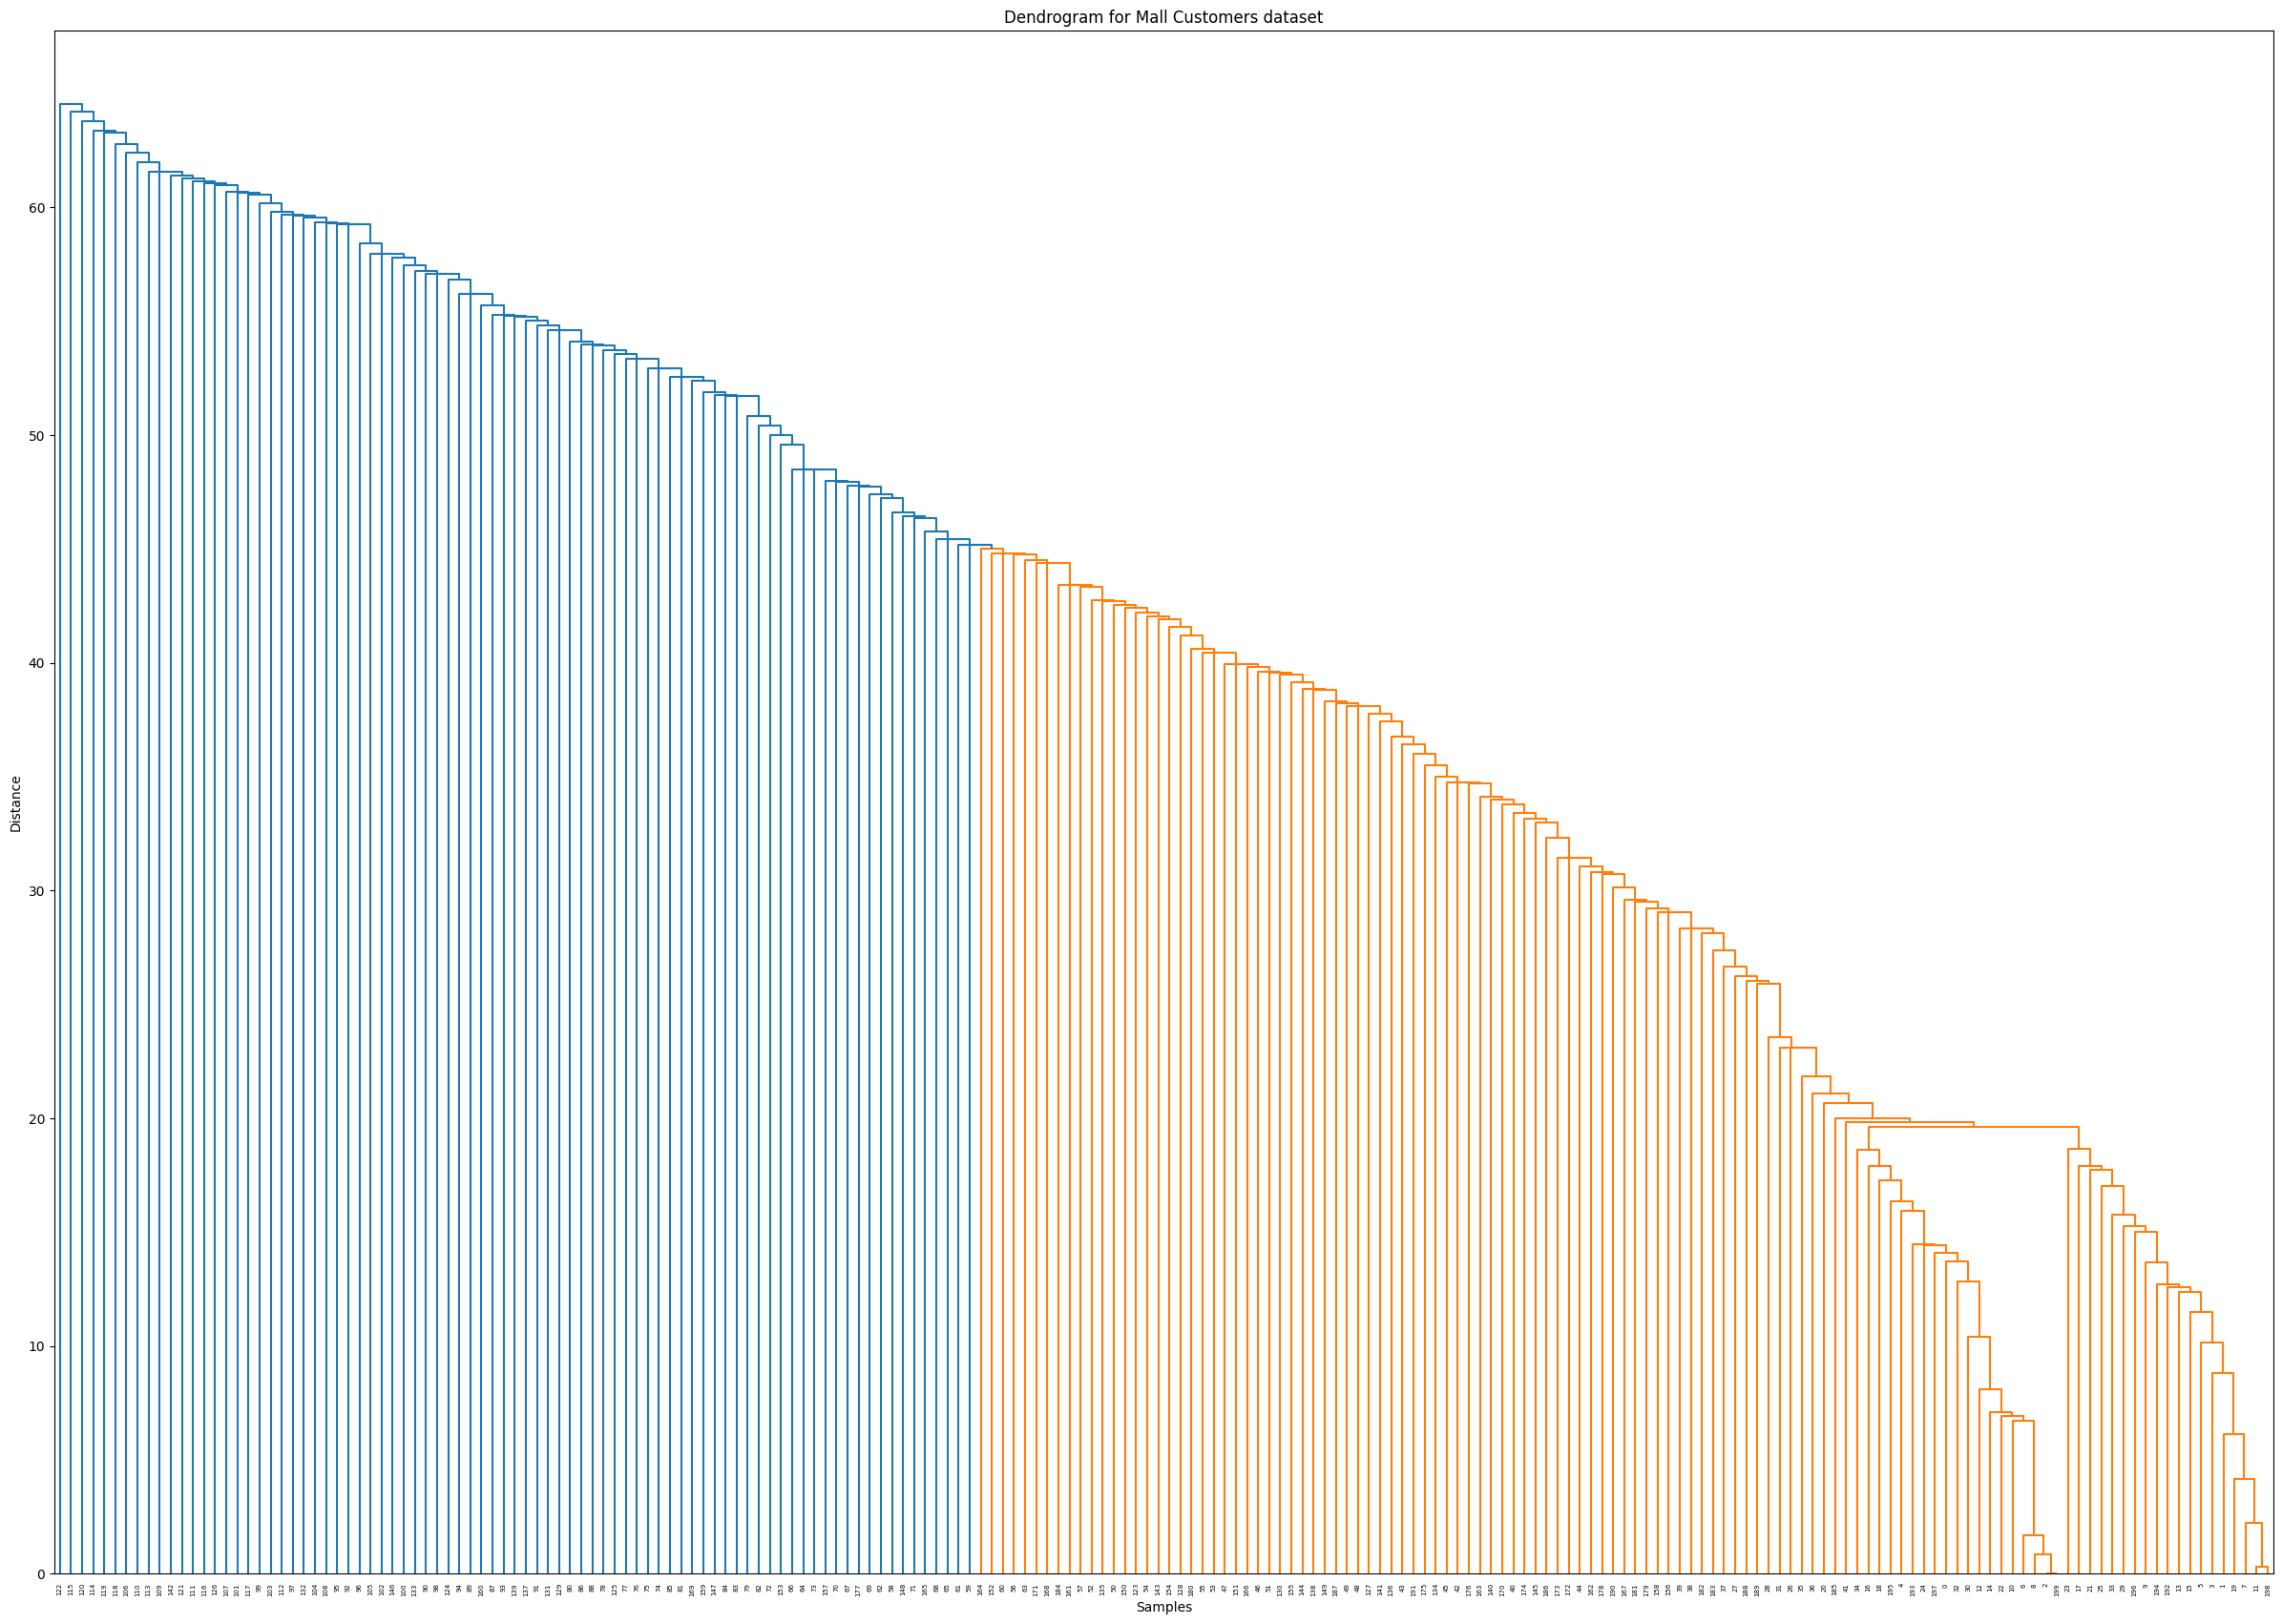

In [30]:
data = pd.read_csv('Mall_Customers.csv')
X = data[['Annual Income (k$)', 'Spending Score (1-100)']].values

similarity_matrix = euclidean_distances(X)
def customer_similarity_func(doc1, doc2):
    return similarity_matrix[doc1, doc2]
customer_documents = list(range(similarity_matrix.shape[0]))

result_mall = single_linkage_alternative(customer_documents, customer_similarity_func)

plot_dendrogram(convertToScypi(result_mall, similarity_matrix.shape[0], np.max(similarity_matrix)),
                 fig_size=(30,21),
                 title='Dendrogram for Mall Customers dataset',
                 save_as_png=True)

Test with Gene Expression Cancer RNA-Seq dataset (from [Kaggle](https://www.kaggle.com/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016?select=data.csv))

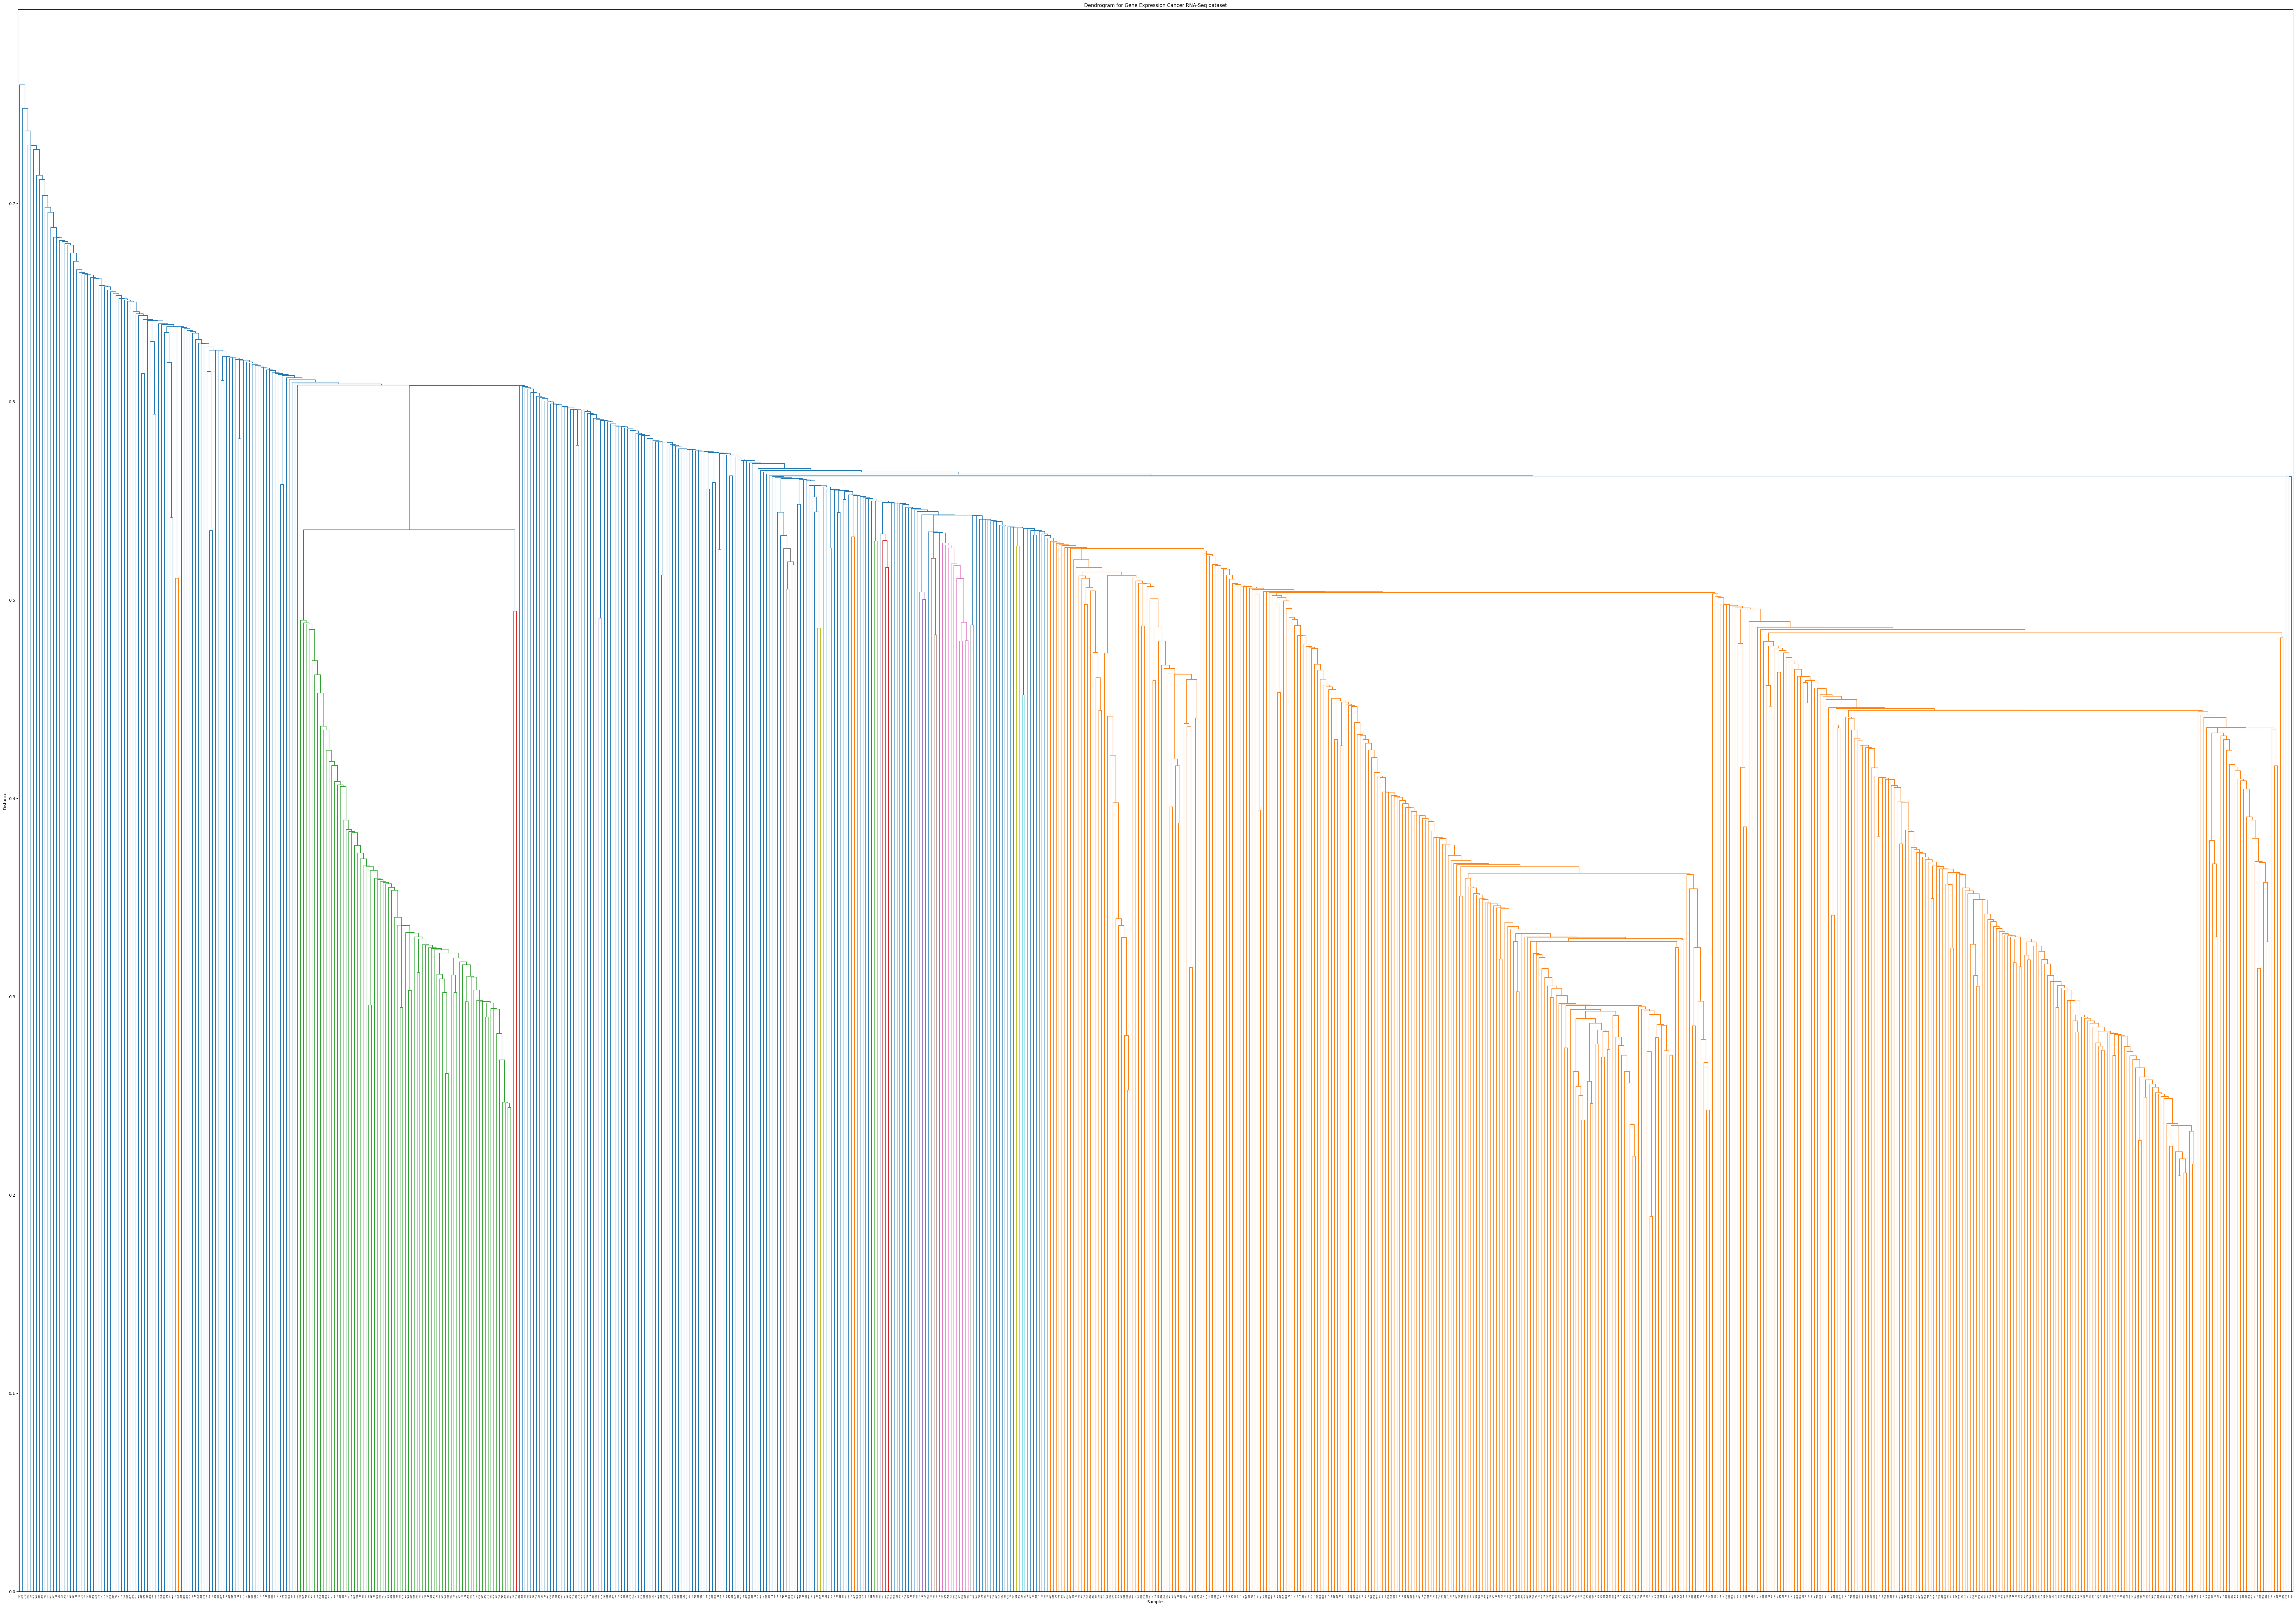

In [31]:
# this is the cell where the error occurs 
path = kagglehub.dataset_download("waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016")

data = pd.read_csv(path + '/data.csv')
data_scaled = StandardScaler().fit_transform(data.iloc[:, 1:])
similarity_matrix = cosine_similarity(data_scaled)
def gene_similarity_func(doc1, doc2):
    return similarity_matrix[doc1, doc2]
documents = list(range(similarity_matrix.shape[0]))
result_gene = single_linkage_alternative(documents, gene_similarity_func)
Z = convertToScypi(result_gene, similarity_matrix.shape[0], np.max(similarity_matrix))
plot_dendrogram(Z, fig_size=(100,70), title='Dendrogram for Gene Expression Cancer RNA-Seq dataset', save_as_png=True)

Test with Gaia Stars Dataset from DR3 Data Release 3 (from [Kaggle](https://www.kaggle.com/datasets/realkiller69/gaia-stars-dataset-from-dr3-data-release-3))

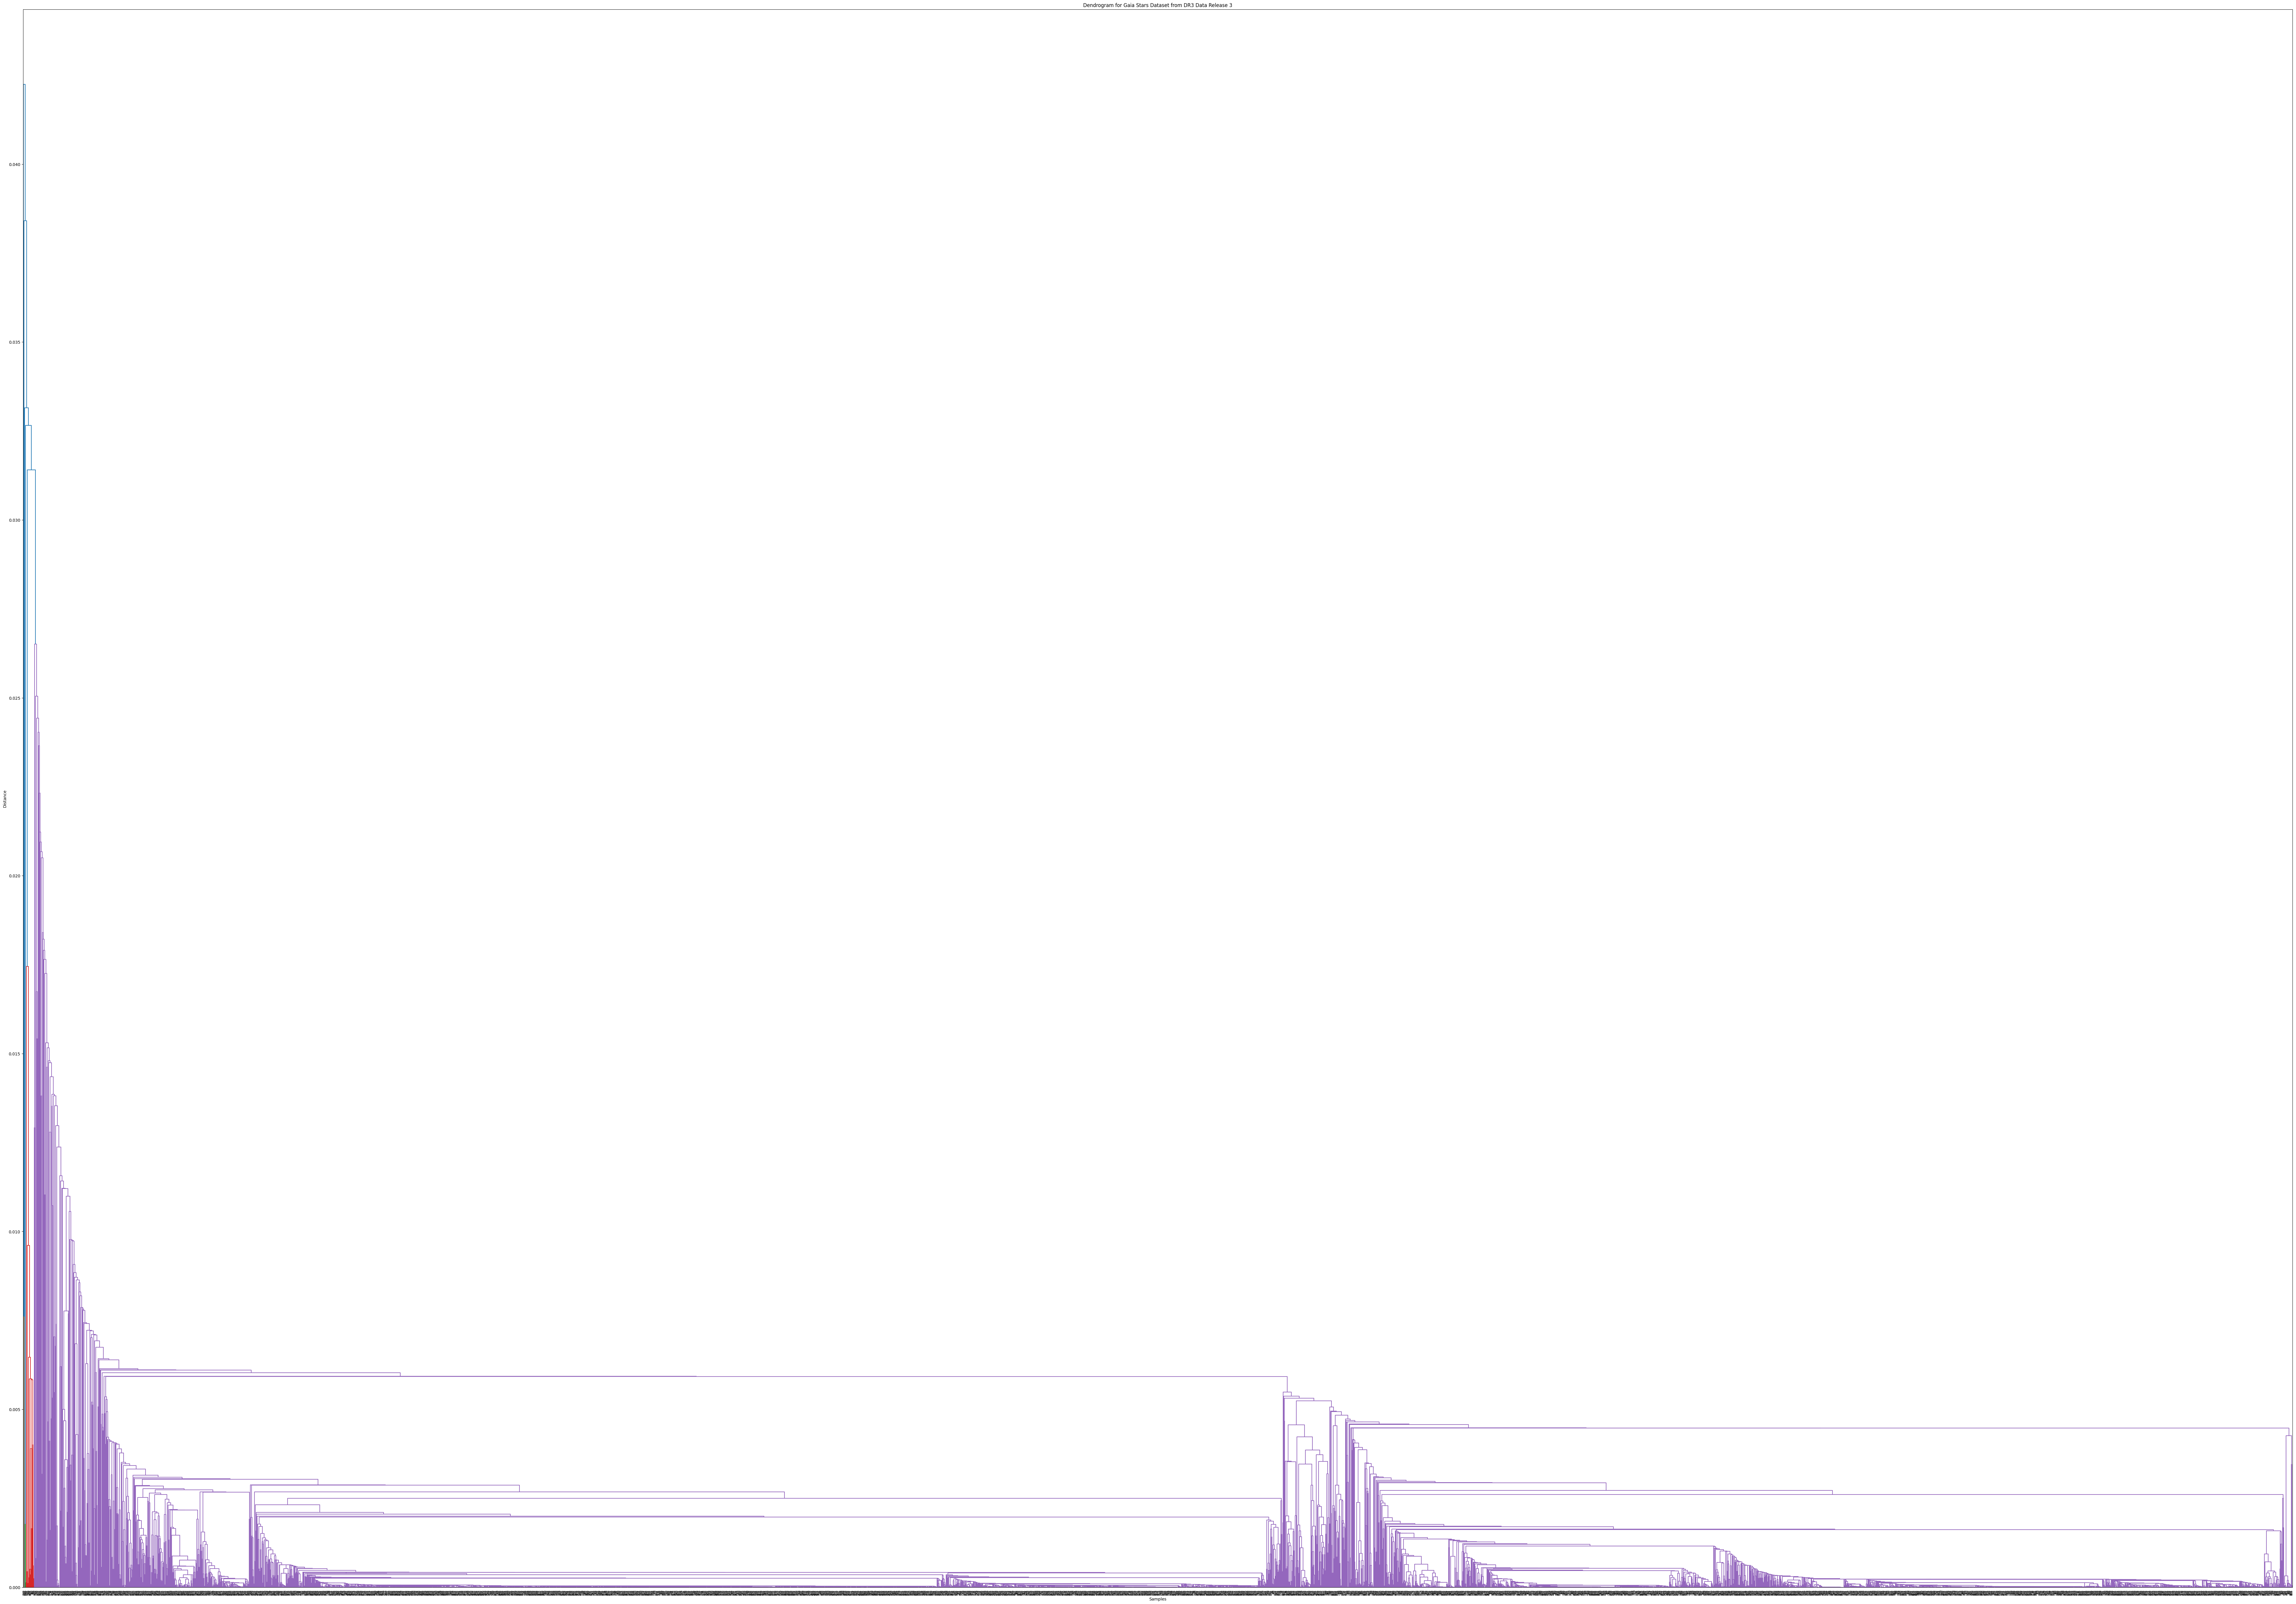

In [32]:
path = kagglehub.dataset_download("realkiller69/gaia-stars-dataset-from-dr3-data-release-3")

data = pd.read_csv(path + '/dataGaia2.csv')

features = ['Teff', 'Lum-Flame', '[Fe/H]'] # Selecting relevant features for clustering main sequence stars
data_clean = data[features].dropna()
data_clean = data_clean.iloc[:5000, :]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_clean)

similarity_matrix = cosine_similarity(X_scaled)
def similarity_func(doc1, doc2):
    return similarity_matrix[doc1, doc2]
documents = list(range(similarity_matrix.shape[0]))


result_gaia = single_linkage_alternative(documents, similarity_func)

Z = convertToScypi(result_gaia, similarity_matrix.shape[0], np.max(similarity_matrix))
plot_dendrogram(Z, fig_size=(100,70), title='Dendrogram for Gaia Stars Dataset from DR3 Data Release 3', save_as_png=True)